# E-commerce Sales & Customer Analytics — Olist (Brazil), Jan 2017 – Aug 2018

**Author:** Jatin Gohel &nbsp;|&nbsp; **Tools:** Python (pandas, NumPy, Matplotlib, Seaborn), SQL (PostgreSQL), Excel, Power BI

## 1. Project introduction

Olist is a Brazilian marketplace that connects small sellers to large online sales channels. Its public dataset
contains ~100K real (anonymised) orders placed between 2016 and 2018, split across customers, orders, items,
payments, reviews, products and sellers.

This notebook takes the raw files through the full workflow:
**raw data → understanding → data-quality checks → cleaning → feature engineering → EDA → KPIs → trends → segments → findings → recommendations.**
It also exports the cleaned, analysis-ready tables used by the Excel workbook and the Power BI dashboard.

> **How to read the numbers:** every number in this notebook is calculated from the raw files in `data/raw/`.
> Nothing is typed in by hand. Re-running the notebook top-to-bottom reproduces every table, chart and KPI.

## 2. Business problem

The commercial team wants a clear picture of **where revenue comes from, who the customers are, and what is hurting
customer experience**, so they can decide where to focus marketing, seller management and logistics effort.

**Questions this analysis answers**

| Area | Question |
|---|---|
| Sales | How much revenue did the marketplace generate, and how is it trending month to month and year over year? |
| Orders | How many orders were delivered, what is the average order value (AOV) and how many orders fail (canceled / unavailable)? |
| Customers | How many unique customers are there, how many come back, and which customer segments matter most? |
| Products | Which categories and products drive revenue, and how concentrated is revenue? |
| Regions | Which states generate the most revenue, and where is shipping cost (freight) a burden? |
| Experience | How do delivery delays affect review scores? |

**What this dataset cannot answer (and is therefore not invented):**
the data has **no product cost, seller commission or marketing spend**, so **profit and profit margin cannot be
calculated**. Where a cost-type signal is useful, the analysis uses **freight as a share of order value**
("freight burden"), which is the shipping charge the customer pays — it is *not* profit.

## 3. Dataset & source

| Item | Detail |
|---|---|
| Dataset | **Brazilian E-Commerce Public Dataset by Olist** |
| Publisher | Olist (Kaggle owner: `olistbr`) |
| Kaggle URL | https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce |
| License (as listed on Kaggle) | CC BY-NC-SA 4.0 — non-commercial use with attribution |
| How the files were obtained | Kaggle could not be reached from the build environment, so the files were taken from two independent public GitHub mirrors of the Kaggle dataset. 7 of 8 files are **byte-for-byte identical (same SHA-256)** across both mirrors; the 8th (category translation) has identical values and differs only in line endings. Details and checksums: `data/raw/SOURCE.md`. |
| Retrieved | 22 Oct 2026 |
| Files used | 8 CSVs (orders, customers, order items, payments, reviews, products, sellers, category translation). The geolocation file (1M rows) is not needed for this analysis and is not included. |

**Table relationships**

```
customers (customer_id) ──< orders (order_id) ──< order_items >── products (product_id)
                                   │                   └──────────< sellers (seller_id)
                                   ├──< payments
                                   └──< reviews
```
`customer_id` is created per order. The real person is `customer_unique_id` — this matters for customer counts.

## 4. Import libraries & chart style

In [1]:
from pathlib import Path
import json
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Folder paths (works when run from the project root or from notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
CLEAN = ROOT / "data" / "cleaned"
REPORTS = ROOT / "reports"
FIG = REPORTS / "figures"
for folder in (CLEAN, FIG):
    folder.mkdir(parents=True, exist_ok=True)

print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

pandas 3.0.5 | numpy 2.5.3 | seaborn 0.13.2


In [2]:
# One consistent, readable chart style for every figure in the project
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, LIGHT_GRAY = PALETTE[0], PALETTE[1], "#c9c7bf"
GOOD, CRITICAL = "#0ca30c", "#d03b3b"   # status colours: only used for good / bad meaning

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.prop_cycle": plt.cycler(color=PALETTE), "lines.linewidth": 2,
    "font.family": "sans-serif", "font.sans-serif": ["Inter", "Segoe UI", "Arial", "DejaVu Sans"],
    "font.size": 10, "legend.frameon": False, "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
})
sns.set_palette(PALETTE)


def brl(x, pos=None):
    """Compact Brazilian Real label: R$1.2M, R$350K, R$90."""
    def trim(v, decimals):
        return f"{v:.{decimals}f}".rstrip("0").rstrip(".")
    if abs(x) >= 1e6:
        return f"R${trim(x / 1e6, 2)}M"
    if abs(x) >= 1e3:
        return f"R${trim(x / 1e3, 1)}K"
    return f"R${x:,.0f}"


def save(fig, name):
    fig.savefig(FIG / f"{name}.png")
    plt.show()

## 5. Load data

In [3]:
files = {
    "orders": "olist_orders_dataset.csv",
    "customers": "olist_customers_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
}

# Zip-code prefixes are codes, not numbers: read them as text so leading zeros (e.g. "01037") are kept.
text_columns = {"customer_zip_code_prefix": str, "seller_zip_code_prefix": str}
raw = {name: pd.read_csv(RAW / file, dtype=text_columns) for name, file in files.items()}

raw["orders"].head(3)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


## 6. Dataset shape

In [4]:
shape = pd.DataFrame(
    {name: {"rows": df.shape[0], "columns": df.shape[1]} for name, df in raw.items()}
).T
shape

,rows,columns
orders,99441,8
customers,99441,5
items,112650,7
payments,103886,5
reviews,100000,7
products,32951,9
sellers,3095,4
category_translation,71,2


## 7. Data types

All timestamps arrive as text and must be converted to `datetime`. Money columns (`price`, `freight_value`,
`payment_value`) are already numeric.

In [5]:
dtypes = pd.concat(
    {name: df.dtypes.astype(str) for name, df in raw.items() if name in ("orders", "items", "payments", "reviews")}
).rename("dtype").to_frame()
dtypes

dtype
orders   order_id                           str
         customer_id                        str
         order_status                       str
         order_purchase_timestamp           str
         order_approved_at                  str
         order_delivered_carrier_date       str
         order_delivered_customer_date      str
         order_estimated_delivery_date      str
items    order_id                           str
         order_item_id                    int64
         product_id                         str
         seller_id                          str
         shipping_limit_date                str
         price                          float64
         freight_value                  float64
payments order_id                           str
         payment_sequential               int64
         payment_type                       str
         payment_installments             int64
         payment_value                  float64
reviews  review_id                          str
         order_id                           str
         review_score                     int64
         review_comment_title               str
         review_comment_message             str
         review_creation_date               str
         review_answer_timestamp            str

## 8. Missing-value analysis

In [6]:
missing = pd.concat({name: df.isna().sum() for name, df in raw.items()}).rename("missing").to_frame()
missing = missing[missing["missing"] > 0]
missing["pct_of_rows"] = [
    round(100 * value / len(raw[table]), 2) for (table, _), value in zip(missing.index, missing["missing"])
]
missing

missing  pct_of_rows
orders   order_approved_at                  160         0.16
         order_delivered_carrier_date      1783         1.79
         order_delivered_customer_date     2965         2.98
reviews  review_comment_title             88285        88.28
         review_comment_message           58247        58.25
products product_category_name              610         1.85
         product_name_lenght                610         1.85
         product_description_lenght         610         1.85
         product_photos_qty                 610         1.85
         product_weight_g                     2         0.01
         product_length_cm                    2         0.01
         product_height_cm                    2         0.01
         product_width_cm                     2         0.01

In [7]:
# Are the missing delivery dates explained by the order status?
orders_raw = raw["orders"]
pd.crosstab(orders_raw["order_status"], orders_raw["order_delivered_customer_date"].notna(),
            rownames=["order_status"], colnames=["has delivery date"], margins=True)

has delivery date,False,True,All
order_status,,,
approved,2,0,2
canceled,619,6,625
created,5,0,5
delivered,8,96470,96478
invoiced,314,0,314
processing,301,0,301
shipped,1107,0,1107
unavailable,609,0,609
All,2965,96476,99441


**What the missing values mean**

* **Delivery / carrier / approval dates** are missing mainly for orders that were never delivered (canceled,
  unavailable, shipped, invoiced...). That is expected, not an error. Only **8 orders marked `delivered` have no
  delivery date** — they are kept for revenue but left out of delivery-time metrics.
* **Review titles and messages** are optional free text, so blanks are normal. Only the 1–5 `review_score` is used.
* **610 products have no category** (and no name/description lengths). They are labelled `Unknown` instead of
  being dropped, because their sales are real revenue.

## 9. Duplicate analysis

In [8]:
duplicate_checks = pd.Series({
    "orders: duplicate order_id": raw["orders"]["order_id"].duplicated().sum(),
    "customers: duplicate customer_id": raw["customers"]["customer_id"].duplicated().sum(),
    "items: duplicate (order_id, order_item_id)": raw["items"].duplicated(["order_id", "order_item_id"]).sum(),
    "products: duplicate product_id": raw["products"]["product_id"].duplicated().sum(),
    "sellers: duplicate seller_id": raw["sellers"]["seller_id"].duplicated().sum(),
    "reviews: fully identical rows": raw["reviews"].duplicated().sum(),
    "reviews: review_id used more than once": raw["reviews"]["review_id"].duplicated().sum(),
    "reviews: orders with more than one review": (raw["reviews"]["order_id"].value_counts() > 1).sum(),
}, name="count")
print("Fully duplicated rows per table:", {n: int(df.duplicated().sum()) for n, df in raw.items()})
duplicate_checks.to_frame()

Fully duplicated rows per table: {'orders': 0, 'customers': 0, 'items': 0, 'payments': 0, 'reviews': 0, 'products': 0, 'sellers': 0, 'category_translation': 0}


,count
orders: duplicate order_id,0
customers: duplicate customer_id,0
"items: duplicate (order_id, order_item_id)",0
products: duplicate product_id,0
sellers: duplicate seller_id,0
reviews: fully identical rows,0
reviews: review_id used more than once,827
reviews: orders with more than one review,555


In [9]:
customers_raw = raw["customers"]
print(f"customer_id values:        {customers_raw['customer_id'].nunique():,}")
print(f"customer_unique_id values: {customers_raw['customer_unique_id'].nunique():,}")

customer_id values:        99,441
customer_unique_id values: 96,096


* No table has fully duplicated rows and every primary key is unique.
* **Reviews:** some orders have more than one review (the customer reviewed again), and some `review_id`s are
  shared by several orders. To get **one score per order**, only the latest answered review is kept.
* **Customers:** `customer_id` is generated per order, so the same person appears with several ids.
  `customer_unique_id` identifies the person — using `customer_id` would hide every repeat purchase.

## 10. Data-quality checks

In [10]:
orders = raw["orders"].copy()
order_dates = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
               "order_delivered_customer_date", "order_estimated_delivery_date"]
for col in order_dates:
    orders[col] = pd.to_datetime(orders[col])

# Check 1 - how many orders per month? (are there incomplete months at the edges?)
orders_per_month = orders.groupby(orders["order_purchase_timestamp"].dt.to_period("M")).size()
print("First months:\n", orders_per_month.head(4).to_string())
print("Last months:\n", orders_per_month.tail(4).to_string())

First months:
 order_purchase_timestamp
2016-09      4
2016-10    324
2016-12      1
2017-01    800
Freq: M
Last months:
 order_purchase_timestamp
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M


In [11]:
dq = {}
# Check 2 - timestamps that are in an impossible order
dq["carrier pickup before purchase"] = (orders["order_delivered_carrier_date"] < orders["order_purchase_timestamp"]).sum()
dq["delivered to customer before carrier pickup"] = (orders["order_delivered_customer_date"] < orders["order_delivered_carrier_date"]).sum()
dq["delivered before purchase"] = (orders["order_delivered_customer_date"] < orders["order_purchase_timestamp"]).sum()
# Check 3 - status and dates that disagree
dq["status 'delivered' but no delivery date"] = ((orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].isna()).sum()
dq["status 'canceled' but has a delivery date"] = ((orders["order_status"] == "canceled") & orders["order_delivered_customer_date"].notna()).sum()
# Check 4 - orders with no items / no payment record
dq["orders with no items"] = (~orders["order_id"].isin(raw["items"]["order_id"])).sum()
dq["orders with no payment record"] = (~orders["order_id"].isin(raw["payments"]["order_id"])).sum()
# Check 5 - payment anomalies
dq["payments with value 0"] = (raw["payments"]["payment_value"] == 0).sum()
dq["payments with type 'not_defined'"] = (raw["payments"]["payment_type"] == "not_defined").sum()
dq["payments with 0 installments"] = (raw["payments"]["payment_installments"] == 0).sum()
# Check 6 - items with free shipping (freight = 0) - valid, but worth knowing
dq["items with freight = 0 (free shipping)"] = (raw["items"]["freight_value"] == 0).sum()
# Check 7 - categories that have no English translation
missing_translation = sorted(set(raw["products"]["product_category_name"].dropna())
                             - set(raw["category_translation"]["product_category_name"]))
dq["categories missing an English name"] = len(missing_translation)

dq_summary = pd.Series(dq, name="rows").to_frame()
dq_summary

,rows
carrier pickup before purchase,166
delivered to customer before carrier pickup,23
delivered before purchase,0
status 'delivered' but no delivery date,8
status 'canceled' but has a delivery date,6
orders with no items,775
orders with no payment record,1
payments with value 0,9
payments with type 'not_defined',3
payments with 0 installments,2


In [12]:
print("Statuses of orders with no items:", orders.loc[~orders["order_id"].isin(raw["items"]["order_id"]), "order_status"].value_counts().to_dict())
print("Categories without translation:", missing_translation)

# Check 8 - do item totals agree with what customers paid?
item_totals = raw["items"].groupby("order_id")[["price", "freight_value"]].sum().sum(axis=1)
paid = raw["payments"].groupby("order_id")["payment_value"].sum()
recon = pd.concat([item_totals.rename("items_total"), paid.rename("paid")], axis=1, join="inner")
recon["difference"] = recon["paid"] - recon["items_total"]
match_rate = (recon["difference"].abs() <= 0.01).mean()
print(f"Orders where payments match item price + freight (±R$0.01): {match_rate:.2%}")
print(f"Total items+freight R${recon['items_total'].sum():,.2f} vs total paid R${recon['paid'].sum():,.2f}")

Statuses of orders with no items: {'unavailable': 603, 'canceled': 164, 'created': 5, 'invoiced': 2, 'shipped': 1}
Categories without translation: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']


Orders where payments match item price + freight (±R$0.01): 99.61%
Total items+freight R$15,843,409.78 vs total paid R$15,846,280.17


In [13]:
# Check 9 - inconsistent seller city spellings
seller_city_examples = raw["sellers"].loc[
    raw["sellers"]["seller_city"].str.contains(r"[/,\\@]|\d|[^\x00-\x7F]", regex=True), "seller_city"
].unique()
print(len(seller_city_examples), "irregular seller city values, e.g.:", list(seller_city_examples[:8]))

22 irregular seller city values, e.g.: ['auriflama/sp', 'sao paulo / sao paulo', 'são paulo', 'santa barbara d´oeste', '04482255', 'novo hamburgo, rio grande do sul, brasil', 'cariacica / es', 'sbc/sp']


**Data-quality conclusions**

1. **Incomplete months at both ends.** Sep–Dec 2016 has very few orders (and none in Nov 2016) and Sep–Oct 2018
   only has a handful of mostly canceled orders. Including them would distort monthly trends and growth rates, so the
   **analysis window is Jan 2017 – Aug 2018 (20 complete months)**.
2. **Timestamp errors are small and rare.** A few hundred orders have carrier dates that are earlier than the
   purchase or later than the delivery (mostly minutes apart, i.e. clock errors). They are flagged but they do not
   affect any KPI used here (delivery time is measured purchase → customer delivery).
3. **Status/date conflicts.** 8 "delivered" orders have no delivery date and 6 canceled orders have one. They are
   flagged; revenue follows the order status.
4. **Orders without items** are almost all `unavailable` or `canceled` orders — they never generated revenue.
5. **Payments reconcile with item totals for ~99.6% of orders**, so item price + freight is a reliable revenue
   measure. Small differences come from vouchers and installment interest.
6. **Two categories lack an English name** and **seller city names are inconsistent** — both fixed in cleaning.

## 11. Data cleaning

Every cleaning step is written to a **cleaning log** (`reports/cleaning_log.csv`) with the number of rows affected.
The raw files are never modified.

In [14]:
cleaning_log = []


def log(step, table, rows_affected, action):
    cleaning_log.append({"step": step, "table": table, "rows_affected": int(rows_affected), "action": action})


# Step 1 - convert text timestamps to datetime (orders already converted above)
log("Convert 5 order timestamp columns to datetime", "orders", len(orders), "type conversion")

items = raw["items"].copy()
items["shipping_limit_date"] = pd.to_datetime(items["shipping_limit_date"])
log("Convert shipping_limit_date to datetime", "items", len(items), "type conversion")

# Step 2 - products: fix misspelled column names, translate categories, fill missing category
products = raw["products"].rename(columns={
    "product_name_lenght": "product_name_length",
    "product_description_lenght": "product_description_length",
})
log("Rename misspelled columns (lenght -> length)", "products", 0, "standardisation (column names)")

translation = pd.concat([
    raw["category_translation"],
    pd.DataFrame({
        "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
        "product_category_name_english": ["pc_gamer", "portable_kitchen_food_preparers"],
    }),
], ignore_index=True)
log("Add English names for 2 untranslated categories", "category_translation", 2, "manual mapping")

# Fix spelling mistakes in the original English category names
typo_fixes = {"fashio_female_clothing": "fashion_female_clothing", "costruction_tools_garden": "construction_tools_garden",
              "costruction_tools_tools": "construction_tools_tools", "home_confort": "home_comfort"}
typo_rows = translation["product_category_name_english"].isin(typo_fixes)
translation["product_category_name_english"] = translation["product_category_name_english"].replace(typo_fixes)
log("Fix 4 misspelled English category names (e.g. fashio -> fashion)", "category_translation", typo_rows.sum(), "standardisation")

products = products.merge(translation, on="product_category_name", how="left")
log("Fill missing product category with 'Unknown'", "products", products["product_category_name"].isna().sum(), "fill missing")
products["category"] = (products["product_category_name_english"].fillna("unknown")
                        .str.replace("_", " ").str.strip().str.capitalize())
products = products.rename(columns={"product_category_name": "category_pt"}).drop(columns="product_category_name_english")
products[["product_id", "category_pt", "category"]].head()

,product_id,category_pt,category
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,Perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,Art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,Sports leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,Baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,Housewares


In [15]:
# Step 3 - sellers: standardise city names (remove accents, '/state' suffixes, numbers typed as cities)
def clean_city(value):
    if pd.isna(value):
        return "unknown"
    text = unicodedata.normalize("NFKD", str(value)).encode("ascii", "ignore").decode()  # são -> sao
    text = re.split(r"[/,\\]", text)[0]                                                 # 'sbc/sp' -> 'sbc'
    text = re.sub(r"\s+", " ", text).strip().lower()
    return "unknown" if text == "" or text.isdigit() else text


sellers = raw["sellers"].copy()
cleaned_city = sellers["seller_city"].map(clean_city)
log("Standardise seller city names", "sellers", (cleaned_city != sellers["seller_city"]).sum(), "standardisation")
sellers["seller_city"] = cleaned_city

customers = raw["customers"].copy()
customers["customer_city"] = customers["customer_city"].str.strip().str.lower()
print("Seller cities before:", raw["sellers"]["seller_city"].nunique(), "after:", sellers["seller_city"].nunique())

Seller cities before: 611 after: 589


In [16]:
# Step 4 - reviews: keep ONE review per order (the latest answered one)
reviews = raw["reviews"].copy()
reviews["review_creation_date"] = pd.to_datetime(reviews["review_creation_date"])
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"])
rows_before = len(reviews)
reviews = (reviews.sort_values(["order_id", "review_answer_timestamp", "review_creation_date", "review_id"])
                  .drop_duplicates(subset="order_id", keep="last"))
log("Keep latest review per order (drop older duplicates)", "reviews", rows_before - len(reviews), "de-duplication")
reviews["has_comment"] = reviews["review_comment_message"].notna()
reviews = reviews.drop(columns=["review_comment_title", "review_comment_message"])  # free text not analysed
print(f"Reviews: {rows_before:,} -> {len(reviews):,} (one per order)")

# Step 5 - payments: 0 installments is impossible -> treat as 1 (single payment)
payments = raw["payments"].copy()
zero_installments = payments["payment_installments"] == 0
payments.loc[zero_installments, "payment_installments"] = 1
log("Set payment_installments 0 -> 1", "payments", zero_installments.sum(), "invalid value fix")
log("Keep 'not_defined' payment type as its own label (value R$0)", "payments",
    (payments["payment_type"] == "not_defined").sum(), "kept + documented")

Reviews: 100,000 -> 99,441 (one per order)


## 12. Feature engineering

Build three analysis tables:

| Table | Grain | Used for |
|---|---|---|
| `fact_orders` | one row per order | revenue, AOV, delivery, reviews, trends (Excel + Power BI) |
| `fact_order_items` | one row per item sold | category, product and seller analysis |
| `dim_customers` | one row per real customer (`customer_unique_id`) | repeat rate, RFM segments |

**Key definitions (used identically in Python, SQL, Excel and Power BI)**

* **Revenue** = item `price` + `freight_value` (what the customer paid for the order). *Product revenue* = price only.
* **Delivered order** = `order_status = 'delivered'`. Revenue KPIs use delivered orders only.
* **Analysis window** = purchases from 2017-01-01 to 2018-08-31.
* **Delivery days** = customer delivery timestamp − purchase timestamp (in days).
* **Late** = delivered on a calendar day after the estimated delivery date.

In [17]:
# Item level: add category, seller state and the revenue of each item
items = (items
         .merge(products[["product_id", "category"]], on="product_id", how="left")
         .merge(sellers[["seller_id", "seller_state"]], on="seller_id", how="left"))
items["item_revenue"] = items["price"] + items["freight_value"]

# Order level: totals from items
order_totals = items.groupby("order_id").agg(
    items_count=("order_item_id", "count"),
    product_revenue=("price", "sum"),
    freight_value=("freight_value", "sum"),
)
# The order's main category = category of its most expensive item (only 0.8% of orders mix categories)
main_category = (items.sort_values(["order_id", "price", "order_item_id"], ascending=[True, False, True])
                      .drop_duplicates("order_id").set_index("order_id")["category"].rename("main_category"))

# Order level: payment summary (main payment type = the method that paid the largest amount)
payment_summary = (payments.sort_values(["order_id", "payment_value", "payment_sequential"], ascending=[True, False, True])
                   .groupby("order_id")
                   .agg(payment_total=("payment_value", "sum"),
                        primary_payment_type=("payment_type", "first"),
                        max_installments=("payment_installments", "max")))
order_totals.head()

,items_count,product_revenue,freight_value
order_id,,,
00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29
00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93
000229ec398224ef6ca0657da4fc703e,1,199.00,17.87
00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79
00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14


In [18]:
fo = (orders
      .merge(customers[["customer_id", "customer_unique_id", "customer_city", "customer_state"]], on="customer_id", how="left")
      .merge(order_totals, on="order_id", how="left")
      .merge(main_category, on="order_id", how="left")
      .merge(payment_summary, on="order_id", how="left")
      .merge(reviews[["order_id", "review_score"]], on="order_id", how="left"))

fo[["items_count", "product_revenue", "freight_value"]] = fo[["items_count", "product_revenue", "freight_value"]].fillna(0)
fo["items_count"] = fo["items_count"].astype(int)
fo["max_installments"] = fo["max_installments"].astype("Int64")   # nullable integer (1 order has no payment record)
fo["order_revenue"] = fo["product_revenue"] + fo["freight_value"]

# Flags
fo["is_delivered"] = fo["order_status"].eq("delivered")
fo["is_canceled"] = fo["order_status"].isin(["canceled", "unavailable"])
WINDOW_START, WINDOW_END = pd.Timestamp("2017-01-01"), pd.Timestamp("2018-09-01")
fo["in_analysis_window"] = (fo["order_purchase_timestamp"] >= WINDOW_START) & (fo["order_purchase_timestamp"] < WINDOW_END)

# Date parts
ts = fo["order_purchase_timestamp"]
fo["purchase_date"] = ts.dt.normalize()
fo["year_month"] = ts.dt.strftime("%Y-%m")
fo["purchase_year"] = ts.dt.year
fo["purchase_weekday"] = ts.dt.day_name()
fo["purchase_hour"] = ts.dt.hour

# Delivery metrics - only for delivered orders that have a delivery date
has_delivery = fo["is_delivered"] & fo["order_delivered_customer_date"].notna()
fo["delivery_days"] = ((fo["order_delivered_customer_date"] - ts).dt.total_seconds() / 86400).where(has_delivery).round(2)
fo["delay_days"] = (fo["order_delivered_customer_date"].dt.normalize() - fo["order_estimated_delivery_date"]).dt.days.where(has_delivery).astype("Int64")
fo["is_late"] = (fo["delay_days"] > 0).astype("boolean").where(has_delivery)

# Data-quality flag (kept for transparency, not removed)
issues = pd.Series("", index=fo.index)
issues = issues.mask(fo["order_delivered_carrier_date"] < ts, "carrier_date_before_purchase")
issues = issues.mask(fo["order_delivered_customer_date"] < fo["order_delivered_carrier_date"], "delivered_before_carrier_pickup")
issues = issues.mask(fo["is_delivered"] & fo["order_delivered_customer_date"].isna(), "delivered_without_delivery_date")
issues = issues.mask((fo["order_status"] == "canceled") & fo["order_delivered_customer_date"].notna(), "canceled_with_delivery_date")
fo["dq_issue"] = issues.replace("", np.nan)
log("Flag orders with timestamp/status conflicts (kept, not removed)", "orders", fo["dq_issue"].notna().sum(), "flag")
log("Exclude orders outside Jan 2017-Aug 2018 from KPIs (kept in file)", "orders", (~fo["in_analysis_window"]).sum(), "scope flag")

print(fo.shape)
fo[["order_id", "order_status", "order_revenue", "delivery_days", "delay_days", "is_late", "review_score"]].head()

(99441, 32)


,order_id,order_status,order_revenue,delivery_days,delay_days,is_late,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,38.71,8.44,-8,False,4
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,141.46,13.78,-6,False,4
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,179.12,9.39,-18,False,5
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,72.20,13.21,-13,False,5
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,28.62,2.87,-10,False,5


In [19]:
# The analysis scope used for every KPI: delivered orders inside the window
delivered = fo[fo["is_delivered"] & fo["in_analysis_window"]].copy()
window_orders = fo[fo["in_analysis_window"]]
items_d = items[items["order_id"].isin(delivered["order_id"])].merge(
    delivered[["order_id", "customer_state", "year_month", "purchase_date"]], on="order_id", how="left")

# Customer level (real person = customer_unique_id) + simple RFM scores
REFERENCE_DATE = pd.Timestamp("2018-09-01")   # day after the last date in the window
cust = delivered.sort_values("order_purchase_timestamp").groupby("customer_unique_id").agg(
    customer_state=("customer_state", "last"),
    customer_city=("customer_city", "last"),
    first_purchase_date=("purchase_date", "min"),
    last_purchase_date=("purchase_date", "max"),
    orders_count=("order_id", "nunique"),
    total_revenue=("order_revenue", "sum"),
)
cust["total_revenue"] = cust["total_revenue"].round(2)          # money: keep 2 decimals (same as SQL NUMERIC)
cust["avg_order_value"] = cust["total_revenue"] / cust["orders_count"]
cust["recency_days"] = (REFERENCE_DATE - cust["last_purchase_date"]).dt.days
cust["is_repeat_customer"] = cust["orders_count"] >= 2

# Quartile thresholds (the same thresholds are re-computed in SQL with PERCENTILE_CONT)
r_q = cust["recency_days"].quantile([0.25, 0.50, 0.75])
m_q = cust["total_revenue"].quantile([0.25, 0.50, 0.75])
cust["r_score"] = np.select([cust["recency_days"] <= r_q[0.25], cust["recency_days"] <= r_q[0.50],
                             cust["recency_days"] <= r_q[0.75]], [4, 3, 2], default=1)
cust["m_score"] = np.select([cust["total_revenue"] > m_q[0.75], cust["total_revenue"] > m_q[0.50],
                             cust["total_revenue"] > m_q[0.25]], [4, 3, 2], default=1)

high_value = cust["m_score"] == 4      # top 25% by spend
recent = cust["r_score"] >= 3           # bought in the more recent half
cust["segment"] = np.select(
    [cust["is_repeat_customer"], high_value & recent, high_value & ~recent, ~high_value & recent],
    ["Repeat customers", "High-value recent", "High-value lapsed", "Regular recent"],
    default="Regular lapsed",
)
print("Recency quartiles (days):", r_q.round(1).to_dict())
print("Spend quartiles (R$):", m_q.round(2).to_dict())
cust["segment"].value_counts()

Recency quartiles (days): {0.25: 117.0, 0.5: 221.0, 0.75: 348.0}
Spend quartiles (R$): {0.25: 63.01, 0.5: 107.78, 0.75: 182.42}


segment
Regular lapsed       34543
Regular recent       34259
High-value recent    10882
High-value lapsed    10631
Repeat customers      2789
Name: count, dtype: int64

In [20]:
# State lookup: the dataset only has 2-letter state codes. Add the state name and the official IBGE
# macro-region (reference data, not from Olist) so results can be shown by region and on a map.
regions = {
    "North": ["AC", "AP", "AM", "PA", "RO", "RR", "TO"],
    "Northeast": ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"],
    "Center-West": ["DF", "GO", "MT", "MS"],
    "Southeast": ["ES", "MG", "RJ", "SP"],
    "South": ["PR", "RS", "SC"],
}
state_names = {
    "AC": "Acre", "AL": "Alagoas", "AP": "Amapá", "AM": "Amazonas", "BA": "Bahia", "CE": "Ceará",
    "DF": "Distrito Federal", "ES": "Espírito Santo", "GO": "Goiás", "MA": "Maranhão", "MT": "Mato Grosso",
    "MS": "Mato Grosso do Sul", "MG": "Minas Gerais", "PA": "Pará", "PB": "Paraíba", "PR": "Paraná",
    "PE": "Pernambuco", "PI": "Piauí", "RJ": "Rio de Janeiro", "RN": "Rio Grande do Norte",
    "RS": "Rio Grande do Sul", "RO": "Rondônia", "RR": "Roraima", "SC": "Santa Catarina", "SP": "São Paulo",
    "SE": "Sergipe", "TO": "Tocantins",
}
dim_state = pd.DataFrame(
    [(code, state_names[code], region) for region, codes in regions.items() for code in codes],
    columns=["state_code", "state_name", "region"],
).sort_values("state_code")
assert set(fo["customer_state"].dropna()) <= set(dim_state["state_code"]), "unknown state code found"
dim_state["map_location"] = dim_state["state_name"] + ", Brazil"   # helps Power BI geocode the map
dim_state.to_csv(CLEAN / "dim_state.csv", index=False)
fo["customer_region"] = fo["customer_state"].map(dim_state.set_index("state_code")["region"])
delivered["customer_region"] = delivered["customer_state"].map(dim_state.set_index("state_code")["region"])
dim_state.head()

,state_code,state_name,region,map_location
0,AC,Acre,North,"Acre, Brazil"
7,AL,Alagoas,Northeast,"Alagoas, Brazil"
2,AM,Amazonas,North,"Amazonas, Brazil"
1,AP,Amapá,North,"Amapá, Brazil"
8,BA,Bahia,Northeast,"Bahia, Brazil"


In [21]:
# Export cleaned, analysis-ready tables
fact_orders_cols = [
    "order_id", "customer_unique_id", "customer_state", "customer_region", "customer_city", "order_status",
    "is_delivered", "is_canceled", "in_analysis_window", "order_purchase_timestamp", "purchase_date", "year_month",
    "purchase_year", "purchase_weekday", "purchase_hour", "items_count", "product_revenue", "freight_value",
    "order_revenue", "main_category", "primary_payment_type", "max_installments", "review_score",
    "delivery_days", "delay_days", "is_late", "dq_issue",
]
fact_orders = fo[fact_orders_cols].copy()
fact_orders["purchase_date"] = fact_orders["purchase_date"].dt.date
for col in ["product_revenue", "freight_value", "order_revenue"]:
    fact_orders[col] = fact_orders[col].round(2)
fact_orders.to_csv(CLEAN / "fact_orders.csv", index=False)

fact_items = items.merge(
    fo[["order_id", "customer_state", "purchase_date", "year_month", "order_status", "is_delivered", "in_analysis_window"]],
    on="order_id", how="left")
fact_items["purchase_date"] = fact_items["purchase_date"].dt.date
fact_items = fact_items[["order_id", "order_item_id", "product_id", "seller_id", "category", "seller_state",
                         "customer_state", "purchase_date", "year_month", "order_status", "is_delivered",
                         "in_analysis_window", "price", "freight_value", "item_revenue"]]
fact_items["item_revenue"] = fact_items["item_revenue"].round(2)
fact_items.to_csv(CLEAN / "fact_order_items.csv", index=False)

dim_customers = cust.reset_index()
for col in ["first_purchase_date", "last_purchase_date"]:
    dim_customers[col] = dim_customers[col].dt.date
for col in ["total_revenue", "avg_order_value"]:
    dim_customers[col] = dim_customers[col].round(2)
dim_customers.to_csv(CLEAN / "dim_customers.csv", index=False)

pd.DataFrame(cleaning_log).to_csv(REPORTS / "cleaning_log.csv", index=False)
dq_summary.to_csv(REPORTS / "data_quality_checks.csv")

for f in ["fact_orders.csv", "fact_order_items.csv", "dim_customers.csv"]:
    df = pd.read_csv(CLEAN / f)
    print(f"{f:22s} {df.shape[0]:>7,} rows x {df.shape[1]} cols  ({(CLEAN / f).stat().st_size / 1e6:.1f} MB)")
pd.DataFrame(cleaning_log)

fact_orders.csv         99,441 rows x 27 cols  (23.4 MB)


fact_order_items.csv   112,650 rows x 15 cols  (20.0 MB)


dim_customers.csv       93,104 rows x 13 cols  (10.6 MB)


,step,table,rows_affected,action
0,Convert 5 order timestamp columns to datetime,orders,99441,type conversion
1,Convert shipping_limit_date to datetime,items,112650,type conversion
2,Rename misspelled columns (lenght -> length),products,0,standardisation (column names)
3,Add English names for 2 untranslated categories,category_translation,2,manual mapping
4,Fix 4 misspelled English category names (e.g. ...,category_translation,4,standardisation
5,Fill missing product category with 'Unknown',products,610,fill missing
6,Standardise seller city names,sellers,25,standardisation
7,Keep latest review per order (drop older dupli...,reviews,559,de-duplication
8,Set payment_installments 0 -> 1,payments,2,invalid value fix
9,Keep 'not_defined' payment type as its own lab...,payments,3,kept + documented


## 13. Descriptive statistics (delivered orders, Jan 2017 – Aug 2018)

In [22]:
delivered[["order_revenue", "product_revenue", "freight_value", "items_count", "delivery_days",
           "delay_days", "review_score", "max_installments"]].describe().T

,count,mean,std,min,25%,50%,75%,max
order_revenue,"96,211.00",159.79,218.86,9.59,61.85,105.28,176.23,"13,664.08"
product_revenue,"96,211.00",137.00,209.11,0.85,45.90,86.50,149.90,"13,440.00"
freight_value,"96,211.00",22.78,21.57,0.00,13.85,17.17,24.01,"1,794.96"
items_count,"96,211.00",1.14,0.54,1.00,1.00,1.00,1.00,21.00
delivery_days,"96,203.00",12.54,9.53,0.53,6.76,10.21,15.68,209.63
delay_days,"96,203.00",-11.81,10.09,-147.00,-17.00,-12.00,-7.00,188.00
review_score,"96,211.00",4.14,1.30,1.00,4.00,5.00,5.00,5.00
max_installments,"96,211.00",2.93,2.71,1.00,1.00,2.00,4.00,24.00


In [23]:
# Outliers: flag (not remove) unusually large orders with the IQR rule
q1, q3 = delivered["order_revenue"].quantile([0.25, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
outliers = delivered["order_revenue"] > upper_fence
print(f"IQR upper fence: R${upper_fence:,.2f}")
print(f"Orders above the fence: {outliers.sum():,} ({outliers.mean():.1%}) = {delivered.loc[outliers, 'order_revenue'].sum() / delivered['order_revenue'].sum():.1%} of revenue")
print("Largest order: R$", round(delivered["order_revenue"].max(), 2))

IQR upper fence: R$347.80
Orders above the fence: 7,551 (7.8%) = 33.7% of revenue
Largest order: R$ 13664.08


Order values are **right-skewed**: most orders are small, a few are very large. The IQR rule flags the large ones,
but they are genuine purchases (expensive items such as computers and furniture), so they are **kept** — removing
them would understate revenue. Because of the skew, the **median** is reported next to the mean where it matters.

## 14. Exploratory data analysis

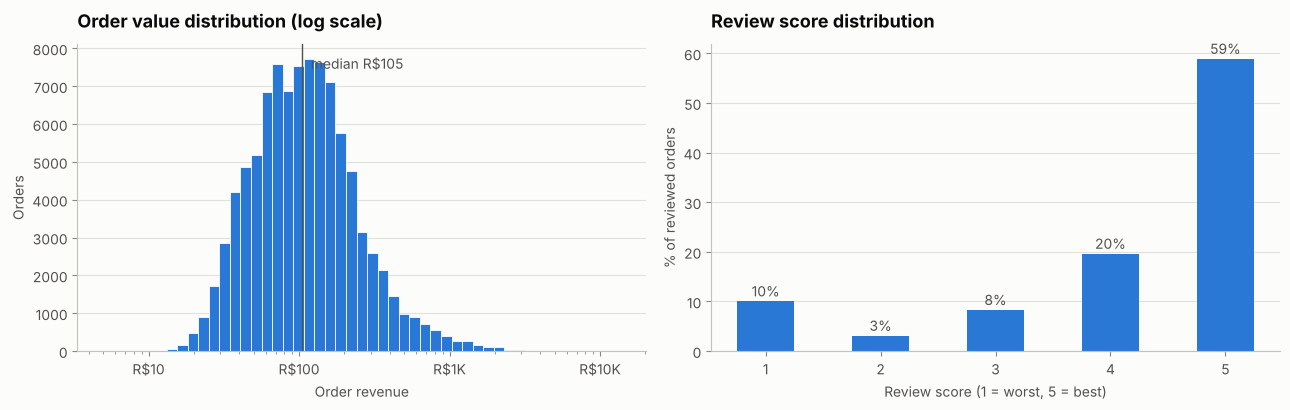

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
bins = np.logspace(np.log10(5), np.log10(delivered["order_revenue"].max()), 50)
ax.hist(delivered["order_revenue"], bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.6)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(brl))
ax.axvline(delivered["order_revenue"].median(), color=INK_2, linewidth=1)
ax.annotate(f"median R${delivered['order_revenue'].median():,.0f}", xy=(delivered["order_revenue"].median(), ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords="offset points", color=INK_2)
ax.set_title("Order value distribution (log scale)")
ax.set_xlabel("Order revenue")
ax.set_ylabel("Orders")
ax.grid(axis="y")

ax = axes[1]
score_share = delivered["review_score"].value_counts(normalize=True).sort_index() * 100
ax.bar(score_share.index.astype(str), score_share.values, color=BLUE, width=0.5)
for x, v in zip(score_share.index.astype(str), score_share.values):
    ax.text(x, v + 1, f"{v:.0f}%", ha="center", color=INK_2)
ax.set_title("Review score distribution")
ax.set_xlabel("Review score (1 = worst, 5 = best)")
ax.set_ylabel("% of reviewed orders")
ax.grid(axis="y")
fig.tight_layout()
save(fig, "01_order_value_and_review_distribution")

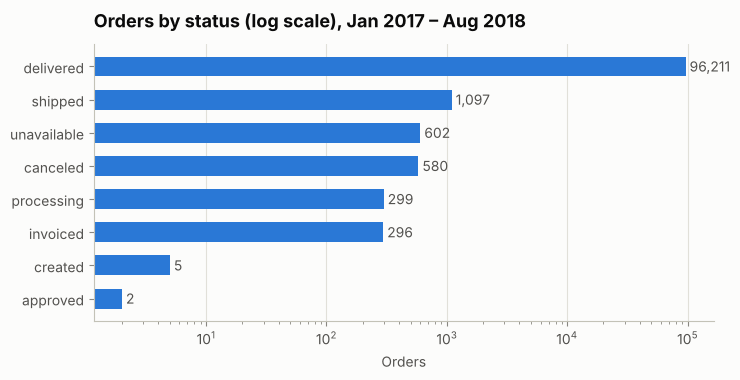

In [25]:
status = window_orders["order_status"].value_counts()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(status.index[::-1], status.values[::-1], color=BLUE, height=0.6)
ax.set_xscale("log")
for y, v in zip(status.index[::-1], status.values[::-1]):
    ax.text(v * 1.08, y, f"{v:,}", va="center", color=INK_2)
ax.set_title("Orders by status (log scale), Jan 2017 – Aug 2018")
ax.set_xlabel("Orders")
ax.grid(axis="x")
save(fig, "02_orders_by_status")

## 15. KPI calculations

In [26]:
total_revenue = delivered["order_revenue"].sum()
kpi = {
    "delivered_orders": len(delivered),
    "total_revenue": total_revenue,
    "product_revenue": delivered["product_revenue"].sum(),
    "freight_revenue": delivered["freight_value"].sum(),
    "avg_order_value": total_revenue / len(delivered),
    "median_order_value": delivered["order_revenue"].median(),
    "unique_customers": delivered["customer_unique_id"].nunique(),
    "repeat_customers": int(cust["is_repeat_customer"].sum()),
    "repeat_customer_rate": cust["is_repeat_customer"].mean(),
    "revenue_per_customer": total_revenue / delivered["customer_unique_id"].nunique(),
    "avg_items_per_order": delivered["items_count"].mean(),
    "freight_share_of_revenue": delivered["freight_value"].sum() / total_revenue,
    "avg_review_score": delivered["review_score"].mean(),
    "five_star_share": (delivered["review_score"] == 5).mean(),
    "low_score_share": delivered["review_score"].isin([1, 2]).mean(),
    "on_time_rate": 1 - delivered["is_late"].dropna().astype(bool).mean(),
    "avg_delivery_days": delivered["delivery_days"].mean(),
    "median_delivery_days": delivered["delivery_days"].median(),
    "orders_in_window": len(window_orders),
    "canceled_or_unavailable_orders": int(window_orders["is_canceled"].sum()),
    "cancellation_rate": window_orders["is_canceled"].mean(),
    "items_sold": len(items_d),
    "active_sellers": items_d["seller_id"].nunique(),
    "categories": items_d["category"].nunique(),
    "states": delivered["customer_state"].nunique(),
}
money = {"total_revenue", "product_revenue", "freight_revenue", "avg_order_value", "median_order_value", "revenue_per_customer"}
rates = {"repeat_customer_rate", "freight_share_of_revenue", "five_star_share", "low_score_share", "on_time_rate", "cancellation_rate"}
decimals = {"avg_items_per_order", "avg_review_score", "avg_delivery_days", "median_delivery_days"}


def show(name, value):
    if name in money:
        return f"R$ {value:,.2f}"
    if name in rates:
        return f"{value:.2%}"
    if name in decimals:
        return f"{value:,.2f}"
    return f"{value:,.0f}"


kpi_table = pd.DataFrame({"KPI": list(kpi), "Value": [show(n, v) for n, v in kpi.items()]})
kpi_table

,KPI,Value
0,delivered_orders,"96,211"
1,total_revenue,"R$ 15,373,120.01"
2,product_revenue,"R$ 13,181,027.13"
3,freight_revenue,"R$ 2,192,092.88"
4,avg_order_value,R$ 159.79
5,median_order_value,R$ 105.28
6,unique_customers,"93,104"
7,repeat_customers,"2,789"
8,repeat_customer_rate,3.00%
9,revenue_per_customer,R$ 165.12


**Why these KPIs:** revenue and delivered orders measure scale; AOV and items per order measure basket size;
unique customers, repeat rate and revenue per customer measure the customer base; on-time rate, delivery days,
cancellation rate and review score measure the customer experience that drives future revenue; freight share shows
how much of every order is shipping cost paid by the customer.

## 16. Trend analysis

In [27]:
monthly = delivered.groupby("year_month").agg(revenue=("order_revenue", "sum"), orders=("order_id", "count"),
                                            customers=("customer_unique_id", "nunique"))
monthly["aov"] = monthly["revenue"] / monthly["orders"]
monthly["revenue_mom_growth_pct"] = monthly["revenue"].pct_change() * 100
monthly.tail(8)

,revenue,orders,customers,aov,revenue_mom_growth_pct
year_month,,,,,
2018-01,"1,077,887.46",7069,6974,152.48,27.85
2018-02,"966,168.41",6555,6400,147.39,-10.36
2018-03,"1,120,598.24",7003,6914,160.02,15.98
2018-04,"1,132,878.93",6798,6744,166.65,1.10
2018-05,"1,128,774.52",6749,6693,167.25,-0.36
2018-06,"1,011,978.29",6099,6061,165.93,-10.35
2018-07,"1,027,807.28",6159,6100,166.88,1.56
2018-08,"985,491.64",6351,6310,155.17,-4.12


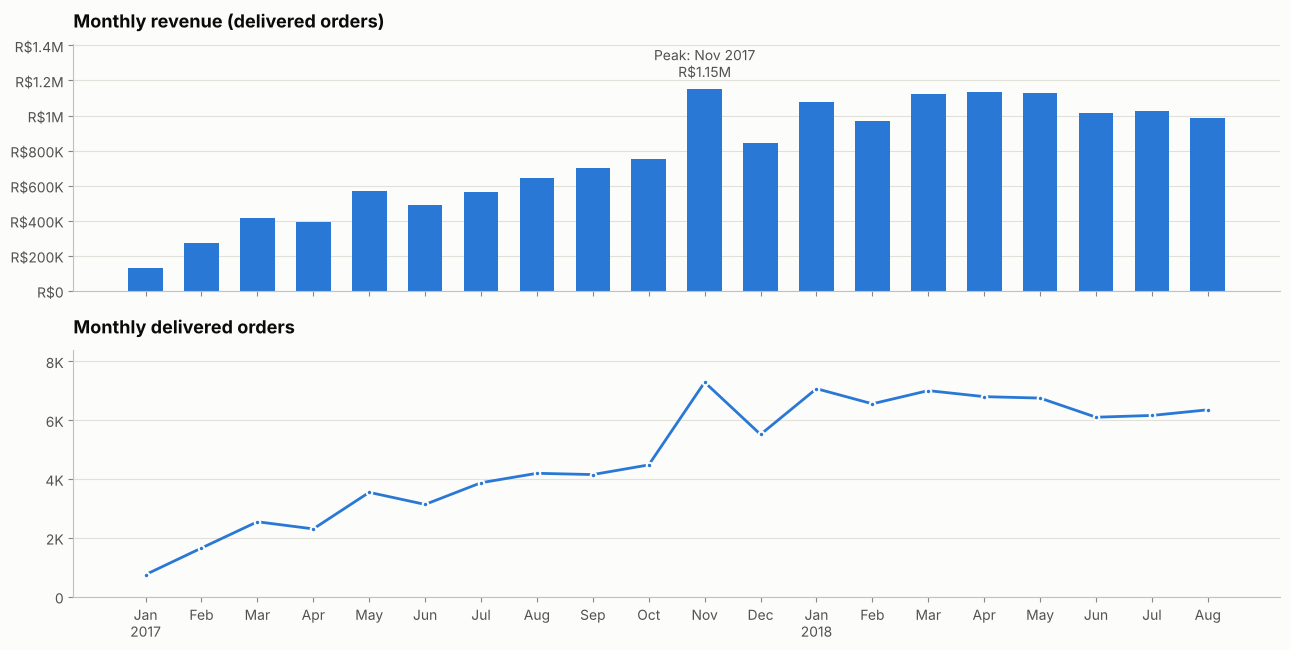

In [28]:
# Two separate panels (revenue and orders) instead of one chart with two y-axes
fig, axes = plt.subplots(2, 1, figsize=(13, 6.6), sharex=True)
x = np.arange(len(monthly))
labels = [pd.Period(m).strftime("%b\n%Y") if m.endswith("-01") or i == 0 else pd.Period(m).strftime("%b")
          for i, m in enumerate(monthly.index)]

ax = axes[0]
ax.bar(x, monthly["revenue"], color=BLUE, width=0.62)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(brl))
peak = monthly["revenue"].idxmax()
ax.annotate(f"Peak: {pd.Period(peak).strftime('%b %Y')}\n{brl(monthly.loc[peak, 'revenue'])}",
            xy=(monthly.index.get_loc(peak), monthly.loc[peak, "revenue"]), xytext=(0, 6),
            textcoords="offset points", ha="center", va="bottom", color=INK_2)
ax.set_ylim(0, monthly["revenue"].max() * 1.22)
ax.set_title("Monthly revenue (delivered orders)")
ax.grid(axis="y")

ax = axes[1]
ax.plot(x, monthly["orders"], color=BLUE, marker="o", markersize=4, markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.set_title("Monthly delivered orders")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: f"{v / 1e3:.0f}K" if v >= 1e3 else f"{v:.0f}"))
ax.set_xticks(x, labels)
ax.set_ylim(0, monthly["orders"].max() * 1.15)
ax.grid(axis="y")
fig.tight_layout()
save(fig, "03_monthly_revenue_and_orders")

In [29]:
# Year-over-year: same months (Jan-Aug) in 2017 vs 2018
jan_aug = delivered[delivered["order_purchase_timestamp"].dt.month <= 8]
yoy = jan_aug.groupby("purchase_year").agg(revenue=("order_revenue", "sum"), orders=("order_id", "count"),
                                          customers=("customer_unique_id", "nunique"))
yoy["aov"] = yoy["revenue"] / yoy["orders"]
yoy_growth = (yoy.loc[2018] / yoy.loc[2017] - 1) * 100
display(yoy)
print("Growth Jan-Aug 2018 vs Jan-Aug 2017 (%):", yoy_growth.round(1).to_dict())

,revenue,orders,customers,aov
purchase_year,,,,
2017,"3,472,898.25",21998,21404,157.87
2018,"8,451,584.77",52783,51612,160.12


Growth Jan-Aug 2018 vs Jan-Aug 2017 (%): {'revenue': 143.4, 'orders': 139.9, 'customers': 141.1, 'aov': 1.4}


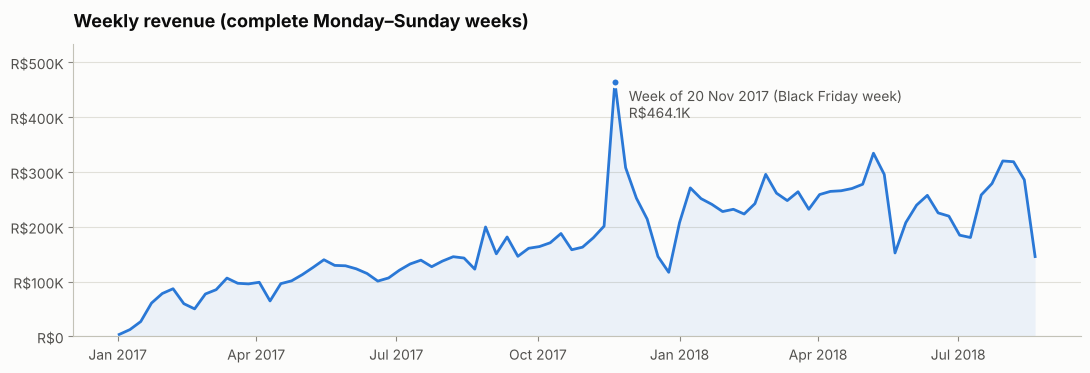

Best single day: Fri 24 Nov 2017 with R$175.2K (7.5x the median day)
Top week contains Black Friday 2017: True


In [30]:
# Weekly revenue - shows short spikes that monthly totals hide
weekly = (delivered.set_index("order_purchase_timestamp")["order_revenue"]
          .resample("W-MON", label="left", closed="left").sum())
weekly = weekly[(weekly.index >= "2017-01-02") & (weekly.index <= "2018-08-20")]   # complete weeks only
daily = delivered.groupby("purchase_date")["order_revenue"].sum()
best_day = daily.idxmax()

import matplotlib.dates as mdates
BLACK_FRIDAY_2017 = pd.Timestamp("2017-11-24")
top_week = weekly.idxmax()
is_black_friday_week = top_week <= BLACK_FRIDAY_2017 < top_week + pd.Timedelta(days=7)

fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(weekly.index, weekly.values, color=BLUE)
ax.fill_between(weekly.index, weekly.values, color=BLUE, alpha=0.08, linewidth=0)
ax.scatter([top_week], [weekly.max()], color=BLUE, s=40, zorder=3, edgecolor=SURFACE, linewidth=2)
label = f"Week of {top_week:%d %b %Y}" + (" (Black Friday week)" if is_black_friday_week else "")
ax.annotate(f"{label}\n{brl(weekly.max())}", xy=(top_week, weekly.max()),
            xytext=(10, -4), textcoords="offset points", va="top", color=INK_2)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(brl))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_ylim(0, weekly.max() * 1.15)
ax.set_title("Weekly revenue (complete Monday–Sunday weeks)")
ax.grid(axis="y")
save(fig, "04_weekly_revenue")
print(f"Best single day: {best_day:%a %d %b %Y} with {brl(daily.max())} "
      f"({daily.max() / daily.median():.1f}x the median day)")
print("Top week contains Black Friday 2017:", is_black_friday_week)

In [31]:
# The weekly line also shows a sharp dip in late May 2018 - check it with daily order counts
orders_per_day = delivered.groupby("purchase_date")["order_id"].count()
before = orders_per_day["2018-05-07":"2018-05-20"].mean()
during = orders_per_day["2018-05-21":"2018-06-03"].mean()
after = orders_per_day["2018-06-04":"2018-06-17"].mean()
print(f"Avg delivered orders per day: 7-20 May 2018 = {before:.0f} | 21 May-3 Jun = {during:.0f} | 4-17 Jun = {after:.0f}")

Avg delivered orders per day: 7-20 May 2018 = 268 | 21 May-3 Jun = 144 | 4-17 Jun = 208


The late-May 2018 dip is real in the data (orders per day fell sharply for about two weeks, then recovered).
The dataset does not say why. One possible explanation is the nationwide **truckers' strike in Brazil (late May 2018)**,
which disrupted deliveries across the country — this is an external event, so treat it as a hypothesis to check with
the business, not as a finding proven by the data.

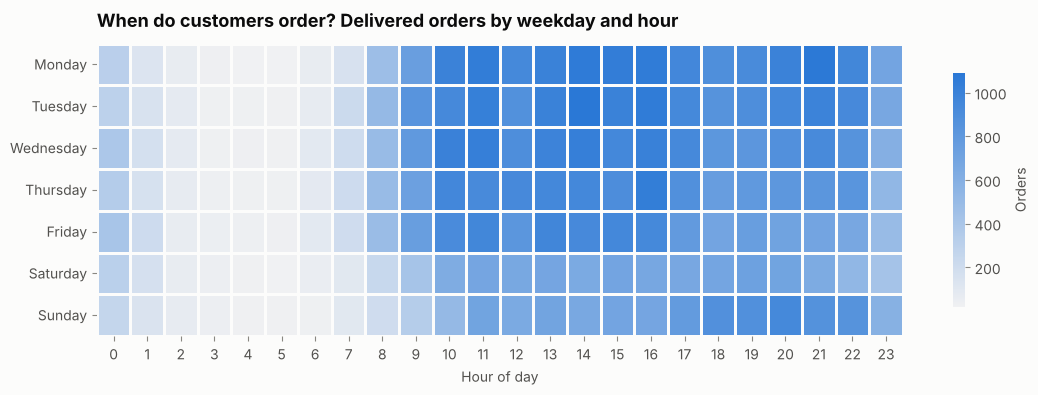

Orders by weekday: {'Monday': 15660, 'Tuesday': 15449, 'Wednesday': 15041, 'Thursday': 14281, 'Friday': 13646, 'Saturday': 10519, 'Sunday': 11615}
Orders placed 10:00-21:59: 75.7%


In [32]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
heat = (delivered.pivot_table(index="purchase_weekday", columns="purchase_hour", values="order_id", aggfunc="count")
        .reindex(weekday_order))
fig, ax = plt.subplots(figsize=(13, 3.8))
sns.heatmap(heat, cmap=sns.light_palette(BLUE, as_cmap=True), linewidths=1, linecolor=SURFACE,
            cbar_kws={"label": "Orders", "shrink": 0.8}, ax=ax)
ax.set_title("When do customers order? Delivered orders by weekday and hour")
ax.set_xlabel("Hour of day")
ax.set_ylabel("")
save(fig, "05_orders_weekday_hour_heatmap")
by_weekday = delivered["purchase_weekday"].value_counts().reindex(weekday_order)
print("Orders by weekday:", by_weekday.to_dict())
print(f"Orders placed 10:00-21:59: {delivered['purchase_hour'].between(10, 21).mean():.1%}")

## 17. Segment analysis

### 17.1 Product categories — revenue, concentration and top/bottom performers

In [33]:
cat = items_d.groupby("category").agg(revenue=("item_revenue", "sum"), items_sold=("order_item_id", "count"),
                                      orders=("order_id", "nunique"), avg_price=("price", "mean"))
cat["revenue_share_pct"] = cat["revenue"] / cat["revenue"].sum() * 100
cat = cat.sort_values("revenue", ascending=False)
cat["cumulative_share_pct"] = cat["revenue_share_pct"].cumsum()
categories_for_80 = int((cat["cumulative_share_pct"] < 80).sum() + 1)
print(f"{len(cat)} categories; the top {categories_for_80} generate 80% of revenue")
cat.head(10)

74 categories; the top 18 generate 80% of revenue


,revenue,items_sold,orders,avg_price,revenue_share_pct,cumulative_share_pct
category,,,,,,
Health beauty,"1,407,759.78",9422,8610,130.50,9.16,9.16
Watches gifts,"1,261,539.41",5855,5491,198.71,8.21,17.36
Bed bath table,"1,224,602.68",10945,9267,93.46,7.97,25.33
Sports leisure,"1,115,766.15",8414,7513,113.24,7.26,32.59
Computers accessories,"1,031,861.93",7632,6518,116.36,6.71,39.30
Furniture decor,"873,430.57",8095,6258,87.24,5.68,44.98
Housewares,"756,849.71",6783,5734,90.57,4.92,49.90
Cool stuff,"690,444.01",3711,3552,164.15,4.49,54.40
Auto,"668,103.48",4132,3802,139.84,4.35,58.74


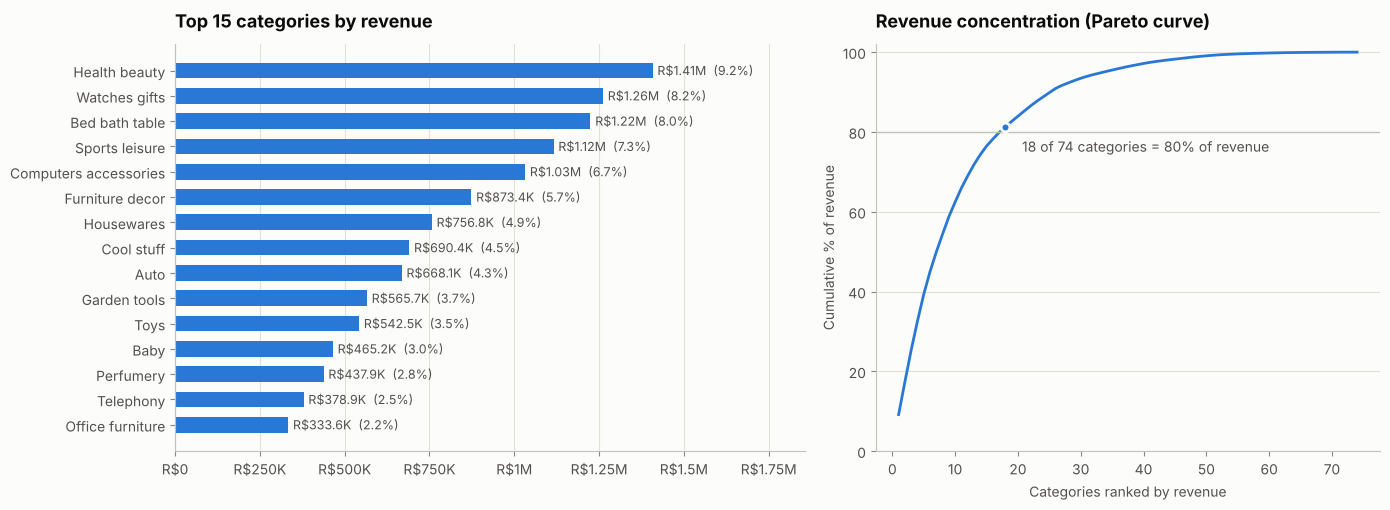

In [34]:
top15 = cat.head(15).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
ax.barh(top15.index, top15["revenue"], color=BLUE, height=0.62)
for y, v, s in zip(top15.index, top15["revenue"], top15["revenue_share_pct"]):
    ax.text(v + top15["revenue"].max() * 0.01, y, f"{brl(v)}  ({s:.1f}%)", va="center", color=INK_2, fontsize=9)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(brl))
ax.set_xlim(0, top15["revenue"].max() * 1.32)
ax.set_title("Top 15 categories by revenue")
ax.grid(axis="x")

ax = axes[1]
rank = np.arange(1, len(cat) + 1)
ax.plot(rank, cat["cumulative_share_pct"], color=BLUE)
ax.axhline(80, color=AXIS, linewidth=1)
ax.scatter([categories_for_80], [cat["cumulative_share_pct"].iloc[categories_for_80 - 1]], color=BLUE, s=40,
           zorder=3, edgecolor=SURFACE, linewidth=2)
ax.annotate(f"{categories_for_80} of {len(cat)} categories = 80% of revenue",
            xy=(categories_for_80, cat["cumulative_share_pct"].iloc[categories_for_80 - 1]),
            xytext=(12, -18), textcoords="offset points", color=INK_2)
ax.set_xlabel("Categories ranked by revenue")
ax.set_ylabel("Cumulative % of revenue")
ax.set_ylim(0, 102)
ax.set_title("Revenue concentration (Pareto curve)")
ax.grid(axis="y")
fig.tight_layout()
save(fig, "06_category_revenue_and_pareto")

In [35]:
# Bottom categories (with at least 30 orders so the comparison is meaningful) and category review scores
cat_reviews = delivered.groupby("main_category").agg(avg_review=("review_score", "mean"), orders=("order_id", "count"))
cat = cat.join(cat_reviews["avg_review"])
print("Bottom 5 categories by revenue (min. 30 orders):")
display(cat[cat["orders"] >= 30].tail(5)[["revenue", "orders", "avg_price", "avg_review"]])
print("Lowest-rated categories (min. 500 orders):")
display(cat[cat["orders"] >= 500].sort_values("avg_review").head(5)[["revenue", "orders", "avg_review"]])

Bottom 5 categories by revenue (min. 30 orders):


,revenue,orders,avg_price,avg_review
category,,,,
Furniture mattress and upholstery,"5,904.75",37,116.85,3.89
Dvds blu ray,"5,769.84",56,74.47,4.18
Party supplies,"5,285.38",38,106.31,4.08
Books imported,"5,150.94",50,77.52,4.44
Fashion female clothing,"3,148.81",35,58.64,3.94


Lowest-rated categories (min. 500 orders):


,revenue,orders,avg_review
category,,,
Office furniture,"333,623.81",1248,3.65
Bed bath table,"1,224,602.68",9267,3.99
Unknown,"197,599.77",1390,4.02
Telephony,"378,868.37",4086,4.05
Furniture decor,"873,430.57",6258,4.07


In [36]:
# Top products (product names are anonymised in the dataset, so products are shown by ID + category)
prod = items_d.groupby(["product_id", "category"]).agg(revenue=("item_revenue", "sum"), units=("order_item_id", "count"))
prod = prod.sort_values("revenue", ascending=False)
units_per_product = items_d.groupby("product_id").size()
print(f"{len(units_per_product):,} products sold; {(units_per_product == 1).mean():.1%} sold only once (long tail)")
print(f"Top 1% of products = {prod['revenue'].head(int(len(prod) * 0.01)).sum() / prod['revenue'].sum():.1%} of revenue")
top_products = prod.head(10).reset_index()
top_products["product_id"] = top_products["product_id"].str[:8] + "…"
top_products

32,081 products sold; 55.0% sold only once (long tail)
Top 1% of products = 23.7% of revenue


,product_id,category,revenue,units
0,bb50f2e2…,Health beauty,"67,258.03",194
1,d1c42706…,Computers accessories,"58,957.31",332
2,6cdd5384…,Health beauty,"57,933.73",153
3,99a4788c…,Bed bath table,"49,907.50",477
4,3dd2a171…,Computers accessories,"47,876.06",272
5,d6160fb7…,Computers,"47,314.18",33
6,aca2eb7d…,Furniture decor,"44,197.75",520
7,5f504b3a…,Cool stuff,"41,725.81",63
8,25c38557…,Baby,"40,311.95",38
9,53b36df6…,Watches gifts,"39,713.49",321


### 17.2 Regions — revenue, order value and freight burden by customer state

In [37]:
state = delivered.groupby("customer_state").agg(revenue=("order_revenue", "sum"), orders=("order_id", "count"),
                                                customers=("customer_unique_id", "nunique"),
                                                freight=("freight_value", "sum"),
                                                avg_delivery_days=("delivery_days", "mean"),
                                                late_rate_pct=("is_late", lambda s: s.dropna().astype(bool).mean() * 100),
                                                avg_review=("review_score", "mean"))
state["aov"] = state["revenue"] / state["orders"]
state["revenue_share_pct"] = state["revenue"] / state["revenue"].sum() * 100
state["freight_share_pct"] = state["freight"] / state["revenue"] * 100
state = state.sort_values("revenue", ascending=False)
state.head(10)

,revenue,orders,customers,freight,avg_delivery_days,late_rate_pct,avg_review,aov,revenue_share_pct,freight_share_pct
customer_state,,,,,,,,,,
SP,"5,755,999.76",40406,39065,"700,412.63",8.74,4.50,4.23,142.45,37.44,12.17
RJ,"2,046,357.64",12310,11879,"294,923.79",15.30,12.14,3.95,166.24,13.31,14.41
MG,"1,813,954.27",11319,10969,"265,747.39",11.98,4.59,4.18,160.26,11.80,14.65
RS,"858,574.68",5328,5151,"132,200.76",15.29,6.10,4.18,161.14,5.58,15.40
PR,"779,214.08",4903,4750,"115,166.08",11.97,4.06,4.23,158.93,5.07,14.78
SC,"592,627.06",3537,3441,"87,852.99",14.95,8.23,4.12,167.55,3.85,14.82
BA,"590,816.80",3253,3155,"97,477.54",19.33,12.17,3.91,181.62,3.84,16.50
DF,"344,923.24",2074,2013,"49,468.60",12.94,5.69,4.13,166.31,2.24,14.34
GO,"333,156.23",1950,1889,"51,224.02",15.61,6.56,4.09,170.85,2.17,15.38


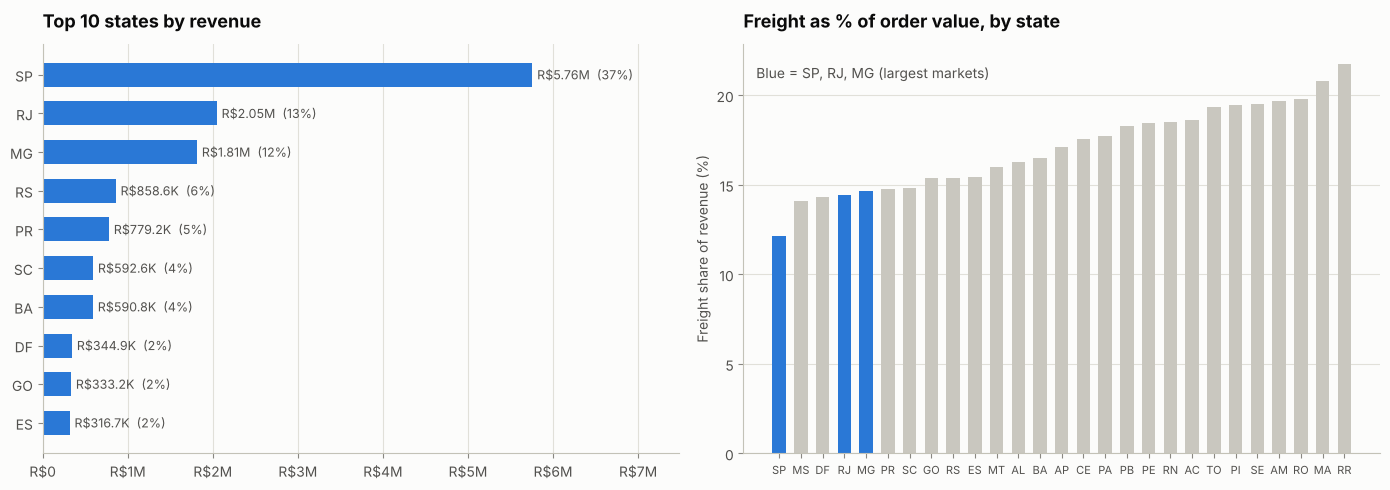

Freight share range across states: 12.2% (SP) to 21.8% (RR)


In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
top10 = state.head(10).iloc[::-1]
ax.barh(top10.index, top10["revenue"], color=BLUE, height=0.62)
for y, v, s in zip(top10.index, top10["revenue"], top10["revenue_share_pct"]):
    ax.text(v + top10["revenue"].max() * 0.01, y, f"{brl(v)}  ({s:.0f}%)", va="center", color=INK_2, fontsize=9)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(brl))
ax.set_xlim(0, top10["revenue"].max() * 1.3)
ax.set_title("Top 10 states by revenue")
ax.grid(axis="x")

ax = axes[1]
fr = state.sort_values("freight_share_pct")
colors = [BLUE if s in ("SP", "RJ", "MG") else LIGHT_GRAY for s in fr.index]
ax.bar(fr.index, fr["freight_share_pct"], color=colors, width=0.62)
ax.set_title("Freight as % of order value, by state")
ax.set_ylabel("Freight share of revenue (%)")
ax.tick_params(axis="x", labelsize=8)
ax.annotate("Blue = SP, RJ, MG (largest markets)", xy=(0.02, 0.95), xycoords="axes fraction", color=INK_2, va="top")
ax.grid(axis="y")
fig.tight_layout()
save(fig, "07_state_revenue_and_freight_burden")
print("Freight share range across states: "
      f"{state['freight_share_pct'].min():.1f}% ({state['freight_share_pct'].idxmin()}) to "
      f"{state['freight_share_pct'].max():.1f}% ({state['freight_share_pct'].idxmax()})")

In [39]:
region = delivered.groupby("customer_region").agg(revenue=("order_revenue", "sum"), orders=("order_id", "count"),
                                                  freight=("freight_value", "sum"),
                                                  avg_delivery_days=("delivery_days", "mean"),
                                                  late_rate_pct=("is_late", lambda s: s.dropna().astype(bool).mean() * 100),
                                                  avg_review=("review_score", "mean"))
region["revenue_share_pct"] = region["revenue"] / region["revenue"].sum() * 100
region["aov"] = region["revenue"] / region["orders"]
region["freight_share_pct"] = region["freight"] / region["revenue"] * 100
region = region.sort_values("revenue", ascending=False)
region[["revenue", "revenue_share_pct", "orders", "aov", "freight_share_pct", "avg_delivery_days", "late_rate_pct", "avg_review"]]

,revenue,revenue_share_pct,orders,aov,freight_share_pct,avg_delivery_days,late_rate_pct,avg_review
customer_region,,,,,,,,
Southeast,"9,932,977.79",64.61,66027,150.44,13.19,10.73,6.13,4.17
South,"2,230,415.82",14.51,13768,162.00,15.03,14.02,5.92,4.18
Northeast,"1,816,169.44",11.81,9015,201.46,17.85,19.99,12.76,3.95
Center-West,"993,570.00",6.46,5610,177.11,14.96,15.01,6.54,4.12
North,"399,986.96",2.60,1791,223.33,18.51,22.59,8.60,4.02


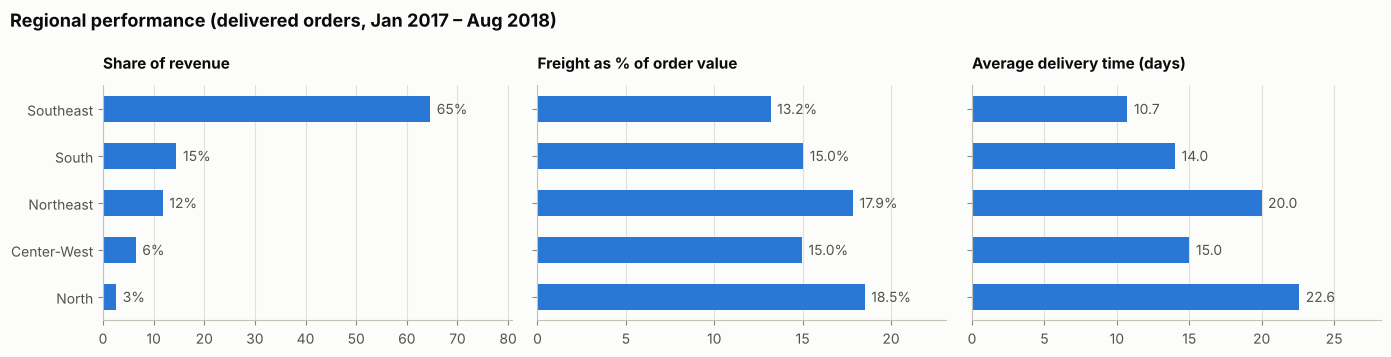

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
y = np.arange(len(region))[::-1]
panels = [("revenue_share_pct", "Share of revenue", "{:.0f}%"),
          ("freight_share_pct", "Freight as % of order value", "{:.1f}%"),
          ("avg_delivery_days", "Average delivery time (days)", "{:.1f}")]
for ax, (column, title, fmt) in zip(axes, panels):
    ax.barh(y, region[column], color=BLUE, height=0.55)
    for yi, v in zip(y, region[column]):
        ax.text(v + region[column].max() * 0.02, yi, fmt.format(v), va="center", color=INK_2)
    ax.set_xlim(0, region[column].max() * 1.25)
    ax.set_title(title, fontsize=11)
    ax.grid(axis="x")
axes[0].set_yticks(y, region.index)
fig.suptitle("Regional performance (delivered orders, Jan 2017 – Aug 2018)",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "07b_region_performance")

### 17.3 Customers — repeat behaviour and RFM segments

In [41]:
seg = dim_customers.groupby("segment").agg(customers=("customer_unique_id", "count"), revenue=("total_revenue", "sum"),
                                           avg_spend=("total_revenue", "mean"), avg_recency_days=("recency_days", "mean"))
seg["customer_share_pct"] = seg["customers"] / seg["customers"].sum() * 100
seg["revenue_share_pct"] = seg["revenue"] / seg["revenue"].sum() * 100
order = ["Repeat customers", "High-value recent", "High-value lapsed", "Regular recent", "Regular lapsed"]
seg = seg.reindex(order)
seg

,customers,revenue,avg_spend,avg_recency_days,customer_share_pct,revenue_share_pct
segment,,,,,,
Repeat customers,2789,"860,533.19",308.55,222.11,3.00,5.60
High-value recent,10882,"4,235,032.15",389.18,114.11,11.69,27.55
High-value lapsed,10631,"4,167,155.02",391.98,366.13,11.42,27.11
Regular recent,34259,"3,063,583.04",89.42,114.33,36.80,19.93
Regular lapsed,34543,"3,046,816.61",88.20,364.87,37.10,19.82


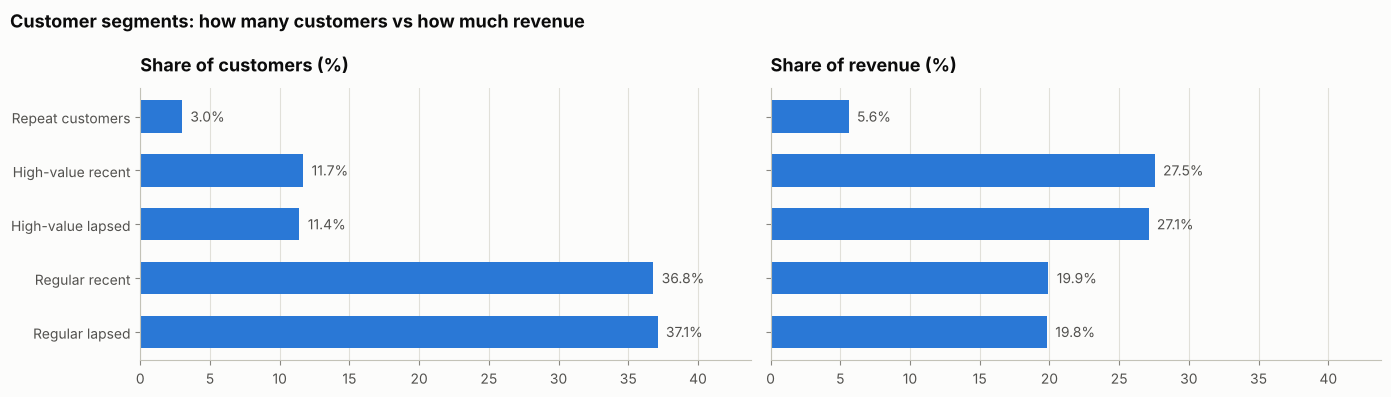

Repeat customers: 2,789 (3.00%); avg spend R$308.55 vs one-time R$160.69


In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
y = np.arange(len(seg))[::-1]
for ax, column, title in [(axes[0], "customer_share_pct", "Share of customers (%)"),
                          (axes[1], "revenue_share_pct", "Share of revenue (%)")]:
    ax.barh(y, seg[column], color=BLUE, height=0.6)
    for yi, v in zip(y, seg[column]):
        ax.text(v + 0.6, yi, f"{v:.1f}%", va="center", color=INK_2)
    ax.set_title(title)
    ax.set_xlim(0, seg[["customer_share_pct", "revenue_share_pct"]].values.max() * 1.18)
    ax.grid(axis="x")
axes[0].set_yticks(y, seg.index)
fig.suptitle("Customer segments: how many customers vs how much revenue", x=0.01, ha="left",
             fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "08_customer_segments")

repeat = dim_customers[dim_customers["is_repeat_customer"]]
print(f"Repeat customers: {len(repeat):,} ({len(repeat) / len(dim_customers):.2%}); "
      f"avg spend R${repeat['total_revenue'].mean():,.2f} vs one-time R${dim_customers.loc[~dim_customers['is_repeat_customer'], 'total_revenue'].mean():,.2f}")

### 17.4 Payments and sellers

In [43]:
pay_mix = delivered.groupby("primary_payment_type").agg(orders=("order_id", "count"), revenue=("order_revenue", "sum"),
                                                        avg_order_value=("order_revenue", "mean"))
pay_mix["order_share_pct"] = pay_mix["orders"] / pay_mix["orders"].sum() * 100
pay_mix = pay_mix.sort_values("orders", ascending=False)
display(pay_mix)

cc = delivered[delivered["primary_payment_type"] == "credit_card"].copy()
cc["installment_band"] = pd.cut(cc["max_installments"], bins=[0, 1, 3, 6, 10, 24], labels=["1", "2-3", "4-6", "7-10", "11+"])
inst = cc.groupby("installment_band", observed=True).agg(orders=("order_id", "count"), avg_order_value=("order_revenue", "mean"))
inst["share_pct"] = inst["orders"] / inst["orders"].sum() * 100
inst

,orders,revenue,avg_order_value,order_share_pct
primary_payment_type,,,,
credit_card,72619,"12,061,504.62",166.09,75.48
boleto,19140,"2,762,300.93",144.32,19.89
voucher,2970,"341,133.08",114.86,3.09
debit_card,1482,"208,181.38",140.47,1.54


,orders,avg_order_value,share_pct
installment_band,,,
1,23313,100.65,32.10
2-3,21961,134.96,30.24
4-6,15643,181.70,21.54
7-10,11373,333.31,15.66
11+,329,359.32,0.45


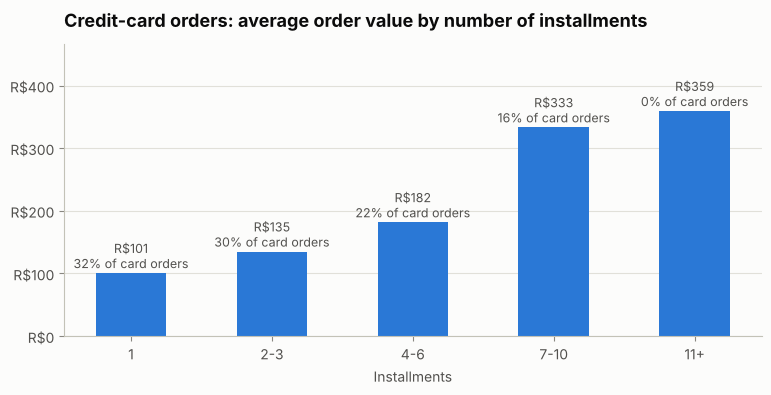

In [44]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(inst.index.astype(str), inst["avg_order_value"], color=BLUE, width=0.5)
for x, v, s in zip(inst.index.astype(str), inst["avg_order_value"], inst["share_pct"]):
    ax.text(x, v + 8, f"{brl(v)}\n{s:.0f}% of card orders", ha="center", color=INK_2, fontsize=9)
ax.set_ylim(0, inst["avg_order_value"].max() * 1.3)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(brl))
ax.set_title("Credit-card orders: average order value by number of installments")
ax.set_xlabel("Installments")
ax.grid(axis="y")
save(fig, "09_installments_vs_order_value")

In [45]:
seller_rev = items_d.groupby("seller_id")["item_revenue"].sum().sort_values(ascending=False)
top10_pct = int(np.ceil(len(seller_rev) * 0.10))
print(f"Active sellers: {len(seller_rev):,}")
print(f"Top 10% of sellers ({top10_pct}) generate {seller_rev.head(top10_pct).sum() / seller_rev.sum():.1%} of revenue")
seller_state = items_d.groupby("seller_state")["item_revenue"].sum().sort_values(ascending=False)
print(f"Sellers based in SP generate {seller_state.get('SP', 0) / seller_state.sum():.1%} of revenue")

Active sellers: 2,945
Top 10% of sellers (295) generate 66.2% of revenue
Sellers based in SP generate 64.6% of revenue


## 18. Correlation analysis — what is linked to review scores?

Correlation shows whether two numbers move together; it does **not** prove that one causes the other.

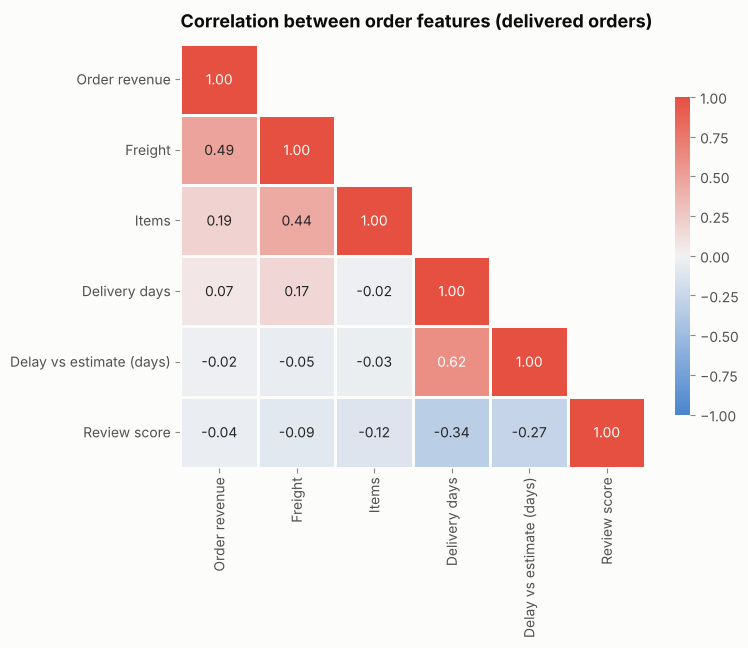

In [46]:
corr_cols = {"order_revenue": "Order revenue", "freight_value": "Freight", "items_count": "Items",
             "delivery_days": "Delivery days", "delay_days": "Delay vs estimate (days)", "review_score": "Review score"}
corr = delivered[list(corr_cols)].rename(columns=corr_cols).corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0,
            cmap=sns.diverging_palette(250, 15, s=75, l=55, as_cmap=True), linewidths=1, linecolor=SURFACE,
            cbar_kws={"shrink": 0.75}, ax=ax)
ax.set_title("Correlation between order features (delivered orders)")
save(fig, "10_correlation_heatmap")

,orders,avg_review,low_score_share
delivery_status,,,
8+ days early,71046,4.31,9.21
0-7 days early,18626,4.18,10.70
1-7 days late,3671,2.69,49.93
8+ days late,2860,1.69,79.48


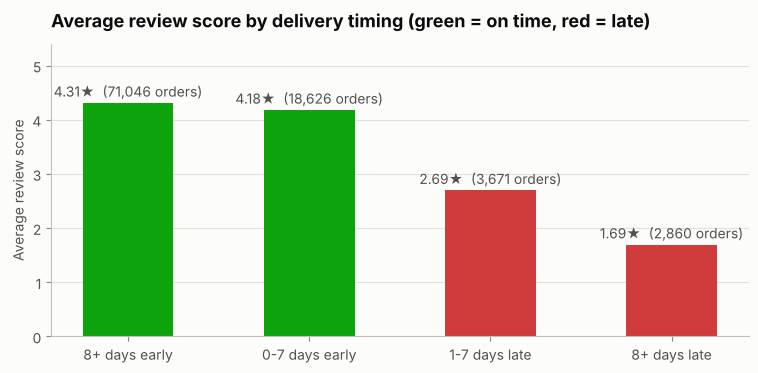

On-time orders avg review 4.28 vs late orders 2.26


In [47]:
d = delivered.dropna(subset=["delay_days", "review_score"]).copy()
d["delivery_status"] = pd.cut(d["delay_days"], bins=[-1000, -8, 0, 7, 1000],
                              labels=["8+ days early", "0-7 days early", "1-7 days late", "8+ days late"])
delay_effect = d.groupby("delivery_status", observed=True).agg(orders=("order_id", "count"),
                                                               avg_review=("review_score", "mean"),
                                                               low_score_share=("review_score", lambda s: s.isin([1, 2]).mean() * 100))
display(delay_effect)

fig, ax = plt.subplots(figsize=(9, 3.8))
colors = [GOOD, GOOD, CRITICAL, CRITICAL]
ax.bar(delay_effect.index.astype(str), delay_effect["avg_review"], color=colors, width=0.5)
for x, v, n in zip(delay_effect.index.astype(str), delay_effect["avg_review"], delay_effect["orders"]):
    ax.text(x, v + 0.12, f"{v:.2f}★  ({n:,} orders)", ha="center", color=INK_2)
ax.set_ylim(0, 5.4)
ax.set_title("Average review score by delivery timing (green = on time, red = late)")
ax.set_ylabel("Average review score")
ax.grid(axis="y")
save(fig, "11_review_score_by_delivery_timing")

late_review = d.loc[d["delay_days"] > 0, "review_score"].mean()
ontime_review = d.loc[d["delay_days"] <= 0, "review_score"].mean()
print(f"On-time orders avg review {ontime_review:.2f} vs late orders {late_review:.2f}")

In [48]:
late_states = state[state["orders"] >= 500].sort_values("late_rate_pct", ascending=False)
late_states[["orders", "late_rate_pct", "avg_delivery_days", "avg_review"]].head(6)

,orders,late_rate_pct,avg_delivery_days,avg_review
customer_state,,,,
MA,713,17.53,21.54,3.81
CE,1273,13.83,21.24,3.93
BA,3253,12.17,19.33,3.91
RJ,12310,12.14,15.30,3.95
PA,942,11.25,23.76,3.89
ES,1992,10.74,15.78,4.05


### Save the KPI summary (used to check every number quoted in the README and reports)

In [49]:
def to_python(v):
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.floating, float)):
        return round(float(v), 4)
    return v

summary = {k: to_python(v) for k, v in kpi.items()}
summary.update({
    "analysis_window": "2017-01-01 to 2018-08-31",
    "orders_raw": int(len(raw["orders"])),
    "customers_raw_ids": int(raw["customers"]["customer_id"].nunique()),
    "customer_unique_ids_raw": int(raw["customers"]["customer_unique_id"].nunique()),
    "items_raw": int(len(raw["items"])),
    "reviews_raw": int(len(raw["reviews"])),
    "reviews_after_dedup": int(len(reviews)),
    "categories_for_80pct_revenue": categories_for_80,
    "top_category": cat.index[0], "top_category_revenue": to_python(cat["revenue"].iloc[0]),
    "top_category_share_pct": to_python(cat["revenue_share_pct"].iloc[0]),
    "top3_categories": list(cat.index[:3]),
    "top3_categories_share_pct": to_python(cat["revenue_share_pct"].head(3).sum()),
    "peak_month": monthly["revenue"].idxmax(), "peak_month_revenue": to_python(monthly["revenue"].max()),
    "best_day": str(best_day.date()), "best_day_revenue": to_python(daily.max()),
    "best_day_vs_median_day": to_python(daily.max() / daily.median()),
    "yoy_revenue_growth_pct": to_python(yoy_growth["revenue"]), "yoy_orders_growth_pct": to_python(yoy_growth["orders"]),
    "yoy_aov_growth_pct": to_python(yoy_growth["aov"]),
    "revenue_jan_aug_2017": to_python(yoy.loc[2017, "revenue"]), "revenue_jan_aug_2018": to_python(yoy.loc[2018, "revenue"]),
    "sp_revenue_share_pct": to_python(state.loc["SP", "revenue_share_pct"]),
    "top3_states_share_pct": to_python(state["revenue_share_pct"].head(3).sum()),
    "sp_freight_share_pct": to_python(state.loc["SP", "freight_share_pct"]),
    "max_freight_state": state["freight_share_pct"].idxmax(), "max_freight_share_pct": to_python(state["freight_share_pct"].max()),
    "min_freight_state": state["freight_share_pct"].idxmin(), "min_freight_share_pct": to_python(state["freight_share_pct"].min()),
    "ontime_avg_review": to_python(ontime_review), "late_avg_review": to_python(late_review),
    "late_8plus_avg_review": to_python(delay_effect.loc["8+ days late", "avg_review"]),
    "late_8plus_low_score_pct": to_python(delay_effect.loc["8+ days late", "low_score_share"]),
    "ontime_low_score_pct": to_python(d.loc[d["delay_days"] <= 0, "review_score"].isin([1, 2]).mean() * 100),
    "late_orders": int((d["delay_days"] > 0).sum()),
    "worst_late_state": late_states.index[0], "worst_late_state_rate_pct": to_python(late_states["late_rate_pct"].iloc[0]),
    "worst_late_state_review": to_python(late_states["avg_review"].iloc[0]),
    "sp_late_rate_pct": to_python(state.loc["SP", "late_rate_pct"]), "sp_avg_delivery_days": to_python(state.loc["SP", "avg_delivery_days"]),
    "credit_card_order_share_pct": to_python(pay_mix.loc["credit_card", "order_share_pct"]),
    "boleto_order_share_pct": to_python(pay_mix.loc["boleto", "order_share_pct"]),
    "cc_single_installment_aov": to_python(inst.loc["1", "avg_order_value"]),
    "cc_7_10_installment_aov": to_python(inst.loc["7-10", "avg_order_value"]),
    "cc_multi_installment_share_pct": to_python(100 - inst.loc["1", "share_pct"]),
    "top10pct_sellers_revenue_share_pct": to_python(seller_rev.head(top10_pct).sum() / seller_rev.sum() * 100),
    "sp_sellers_revenue_share_pct": to_python(seller_state.get("SP", 0) / seller_state.sum() * 100),
    "products_sold": int(len(units_per_product)),
    "products_sold_once_pct": to_python((units_per_product == 1).mean() * 100),
    "repeat_avg_spend": to_python(repeat["total_revenue"].mean()),
    "one_time_avg_spend": to_python(dim_customers.loc[~dim_customers["is_repeat_customer"], "total_revenue"].mean()),
    "repeat_revenue_share_pct": to_python(seg.loc["Repeat customers", "revenue_share_pct"]),
    "high_value_lapsed_customers": int(seg.loc["High-value lapsed", "customers"]),
    "high_value_lapsed_revenue_share_pct": to_python(seg.loc["High-value lapsed", "revenue_share_pct"]),
    "high_value_customer_share_pct": to_python(seg.loc[["High-value recent", "High-value lapsed"], "customer_share_pct"].sum()),
    "high_value_revenue_share_pct": to_python(seg.loc[["High-value recent", "High-value lapsed"], "revenue_share_pct"].sum()),
    "spend_p75": to_python(m_q[0.75]), "recency_p50": to_python(r_q[0.50]),
    "outlier_orders": int(outliers.sum()), "outlier_fence": to_python(upper_fence),
    "payments_match_rate": to_python(match_rate),
    "busiest_weekday": by_weekday.idxmax(), "quietest_weekday": by_weekday.idxmin(),
    "orders_10_to_22_share": to_python(delivered["purchase_hour"].between(10, 21).mean()),
    "corr_delay_review": to_python(corr.loc["Delay vs estimate (days)", "Review score"]),
    "corr_delivery_review": to_python(corr.loc["Delivery days", "Review score"]),
    "seller_cities_raw": int(raw["sellers"]["seller_city"].nunique()),
    "seller_cities_clean": int(sellers["seller_city"].nunique()),
    "mixed_category_orders_pct": to_python((items.groupby("order_id")["category"].nunique() > 1).mean() * 100),
    "zero_value_payments_by_type": raw["payments"].loc[raw["payments"]["payment_value"] == 0, "payment_type"].value_counts().to_dict(),
    "region_revenue_share_pct": {k: to_python(v) for k, v in region["revenue_share_pct"].items()},
    "region_freight_share_pct": {k: to_python(v) for k, v in region["freight_share_pct"].items()},
    "region_avg_delivery_days": {k: to_python(v) for k, v in region["avg_delivery_days"].items()},
    "region_late_rate_pct": {k: to_python(v) for k, v in region["late_rate_pct"].items()},
    "region_avg_review": {k: to_python(v) for k, v in region["avg_review"].items()},
    "may2018_orders_per_day_before": to_python(before), "may2018_orders_per_day_during": to_python(during),
    "may2018_orders_per_day_after": to_python(after),
    "top_week": str(top_week.date()), "top_week_revenue": to_python(weekly.max()),
    "top_week_is_black_friday": bool(is_black_friday_week),
})
(REPORTS / "kpi_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print(f"Saved {len(summary)} values to reports/kpi_summary.json")

Saved 107 values to reports/kpi_summary.json


## 19. Visualisations

All charts above are saved as PNG files in `reports/figures/` (they are also used in the README):

| File | Shows |
|---|---|
| `01_order_value_and_review_distribution.png` | order value skew and review score mix |
| `02_orders_by_status.png` | how many orders fail (canceled / unavailable) |
| `03_monthly_revenue_and_orders.png` | monthly trend in two panels |
| `04_weekly_revenue.png` | weekly trend and the Black Friday spike |
| `05_orders_weekday_hour_heatmap.png` | when customers buy |
| `06_category_revenue_and_pareto.png` | top categories and revenue concentration |
| `07_state_revenue_and_freight_burden.png` | revenue by state and freight burden |
| `08_customer_segments.png` | RFM segments: customers vs revenue |
| `09_installments_vs_order_value.png` | installments and basket size |
| `10_correlation_heatmap.png` | correlations between order features |
| `11_review_score_by_delivery_timing.png` | effect of late delivery on reviews |

## 20. Key findings

1. **Scale.** 96,211 delivered orders from 93,104 unique customers generated **R$15.37M**
   (Jan 2017 – Aug 2018). Average order value (AOV) is **R$159.79**; the median is R$105.28 because a few large orders
   pull the mean up.
2. **Growth came from volume, not basket size.** Jan–Aug 2018 revenue was **143.4%** higher than Jan–Aug 2017
   (R$3.47M → R$8.45M). Orders grew +139.9% while AOV changed only +1.4%.
3. **Black Friday is the biggest moment of the year.** The best day was **Friday 24 November 2017** (Black Friday 2017) with
   **R$175.2K** — **7.5×** a median day. November 2017 was the highest-revenue month (R$1.15M).
4. **Customers rarely come back.** Only **3.0%** of customers placed a second order. Repeat customers spend
   **R$308.55** on average vs **R$160.69** for one-time buyers, but bring only **5.6%** of revenue.
5. **Big one-time spenders matter most.** The two "High-value" segments (one-time buyers in the top 25% by spend) are
   23.1% of customers but **54.7%** of revenue; 10,631 of them last bought more than
   221 days before the end of the data.
6. **Revenue is concentrated in a few categories.** 18 of 74 categories make 80% of revenue; the top 3
   (Health beauty, Watches gifts, Bed bath table) make **25.3%**.
7. **Revenue is concentrated in the South-East.** The South-East region is **64.6%** of revenue and São Paulo (SP)
   alone is **37.4%**.
8. **Customers outside the South-East pay more and wait longer.** Freight is 13.2% of order value in the South-East
   but **18.5%** in the North (highest state: Roraima (RR) at 21.8%). Average delivery takes
   10.7 days in the South-East vs **22.6 days** in the North.
9. **Late delivery is the strongest driver of bad reviews.** On-time orders average **4.28★** vs
   **2.26★** for late orders. Orders 8+ days late average 1.69★ and **79.5%** of them get a
   1–2★ review (vs 9.5% of on-time orders).
10. **Late deliveries are concentrated in the North-East.** Overall 93.2% of orders arrive on time, but the North-East
    late rate is **12.8%** vs 6.1% in the South-East; the worst state (≥500 orders) is Maranhão (MA) at 17.5%.
11. **Installments are linked to bigger baskets.** 75.5% of orders are paid mainly by credit card and 67.9% of
    card orders use installments; 7–10-installment orders average **R$333.31** vs R$100.65 for single payments.
12. **The seller base is concentrated.** The top 10% of sellers generate **66.2%** of revenue, and sellers based in
    SP generate 64.6%.

## 21. Business recommendations

| # | Recommendation | Based on finding |
|---|---|---|
| 1 | **Start a retention programme for first-time buyers** — post-delivery "buy again" offers at 30/60/90 days in the category they bought. Goal: lift the repeat rate from 3.0%. | 4 |
| 2 | **Win back high-value lapsed customers** (10,631 people in the top 25% by spend who have not bought recently) with personalised offers. | 5 |
| 3 | **Reduce late deliveries in the North-East first** (start with Maranhão (MA)): review carriers and routes, add a realistic buffer to the promised date, and message customers before an order becomes late. | 9, 10 |
| 4 | **Test free-shipping thresholds or freight subsidies in the North and North-East**, where freight takes a much bigger share of the basket. | 8 |
| 5 | **Plan stock, seller capacity, carriers and customer service for Black Friday** and the Nov–Jan peak. | 3 |
| 6 | **Protect the top categories and top sellers** (stock availability, seller service levels) and use them as entry points for cross-selling. | 6, 12 |
| 7 | **Promote interest-free installments on higher-priced categories.** | 11 |
| 8 | **Collect cost data next** (product cost, commission, marketing spend) so the next version can measure profit, not only revenue. | Limitation |